# PAL Feature and Baseline Analysis

## Goal
把周度采购历史变成可用于预测的特征，并完成上周量、前4周均值、52周前量三个baseline的**验证期**比较。每个代码格按顺序按 **Shift+Enter** 运行，等待左侧星号消失再继续。

本文件依据上传的 `iowa_liquor_sales_clean.zip`。附带准备段能从交易文件生成周度面板；如果已经有验收后的周度mart，可以直接读取它。这里的准备段不能替代MySQL数仓交付或完整数据审计。

### 关键假设
默认采用固定校准cohort，并**假设清洗文件包含每个完整周应有的全部来源交易**。文件中每周有记录只能排除整周完全空白，不能证明覆盖完整。该假设用于教程试跑，零采购和baseline结果需在团队核实覆盖后才可作为正式报告证据。

预测单位是门店×酒类×周；正向瓶数为目标；预测每周开始前的下一周。验证期间过去周的实际量可以更新后续历史特征，最终测试期不在本教程评价。

In [23]:
from pathlib import Path
import os, json, zipfile, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})
print("Python", platform.python_version(), "pandas", pd.__version__, "numpy", np.__version__)

Python 3.14.6 pandas 3.0.3 numpy 2.4.6


In [24]:
BASE_DIR = Path(os.environ.get("PAL_TUTORIAL_BASE_DIR", Path.cwd()))
WEEKLY_CSV = None  # 示例：BASE_DIR / "MartStoreCategoryWeek.csv"
COVERAGE_MODE = "assumed_complete"  # 或核实之后的 confirmed_complete
OUTPUT_DIR = BASE_DIR / "pal_steps_9_10_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SOURCE_CANDIDATES = [BASE_DIR / "iowa_liquor_sales_clean.zip",
                     BASE_DIR / "upload" / "iowa_liquor_sales_clean.zip",
                     BASE_DIR / "iowa_liquor_sales_clean.csv"]
SOURCE = next((p for p in SOURCE_CANDIDATES if p.exists()), None)
ALL_WEEKS = pd.date_range("2025-01-06", "2026-09-22", freq="W-MON")
KEYS = ["store_no", "category_code"]
assert COVERAGE_MODE in {"assumed_complete", "confirmed_complete"}, "请先处理已知缺失时期"
print("输入", WEEKLY_CSV if WEEKLY_CSV else SOURCE)
print("输出", OUTPUT_DIR)
print("覆盖模式", COVERAGE_MODE, "；正式报告前请核实覆盖。")

输入 C:\Users\sadie\Desktop\PAL\iowa_liquor_sales_clean.zip
输出 C:\Users\sadie\Desktop\PAL\pal_steps_9_10_outputs
覆盖模式 assumed_complete ；正式报告前请核实覆盖。


## Steps
### 0B 附带准备段 交易表转周度数据
已有mart也可直接运行此格，会跳过交易读取。否则分块读取四个必要字段，避免一次装入25列。正向数量汇总为 `y`，负数不会抵扣目标。

此处读取的是清洗后数据；26条缺少酒类编码的记录会从本教程的酒类分析中排除。输入字段必须可解析，不能默默将异常转换成零。完整周之外的记录不会进入周度建模。

In [25]:
if WEEKLY_CSV is not None:
    panel = pd.read_csv(WEEKLY_CSV, dtype={"store_no": str, "category_code": str})
    source_description = str(WEEKLY_CSV)
else:
    if SOURCE is None:
        raise FileNotFoundError("找不到数据：请修改BASE_DIR，或指定WEEKLY_CSV")
    grouped_chunks, weekly_record_counts = [], []
    raw_rows = missing_category = 0
    zip_handle = zipfile.ZipFile(SOURCE) if SOURCE.suffix.lower() == ".zip" else None
    if zip_handle:
        csv_names = [n for n in zip_handle.namelist() if n.lower().endswith(".csv")]
        if len(csv_names) != 1:
            raise ValueError("ZIP内应只有一张CSV；请明确选择要读取的文件")
        reader_input = zip_handle.open(csv_names[0])
    else:
        reader_input = SOURCE
    try:
        reader = pd.read_csv(reader_input,
            usecols=["ordered_on", "store_no", "category_code", "sales_bottles"],
            dtype={"ordered_on": str, "store_no": str, "category_code": str}, chunksize=200_000)
        for chunk in reader:
            raw_rows += len(chunk)
            chunk["ordered_on"] = pd.to_datetime(chunk["ordered_on"], errors="raise")
            q = pd.to_numeric(chunk["sales_bottles"], errors="raise")
            assert q.notna().all() and np.isfinite(q).all(), "数量有缺失或无穷值"
            assert ((q % 1) == 0).all(), "瓶数存在非整数，请核查"
            assert chunk["ordered_on"].notna().all() and chunk["store_no"].notna().all()
            chunk["week_start"] = chunk["ordered_on"] - pd.to_timedelta(
    chunk["ordered_on"].dt.dayofweek,
    unit="D"
)
            chunk["y"] = q.clip(lower=0)
            chunk = chunk[chunk["week_start"].isin(ALL_WEEKS)].copy()
            weekly_record_counts.append(chunk.groupby("week_start").size())
            missing_category += int(chunk["category_code"].isna().sum())
            chunk = chunk.dropna(subset=["category_code"])
            grouped_chunks.append(chunk.groupby(KEYS + ["week_start"], as_index=False)["y"].sum())
    finally:
        if zip_handle:
            reader_input.close(); zip_handle.close()
    record_counts = pd.concat(weekly_record_counts, axis=1).fillna(0).sum(axis=1).reindex(ALL_WEEKS, fill_value=0)
    assert (record_counts > 0).all(), "至少一周完全没有源记录；不可直接补零"
    weekly_all = pd.concat(grouped_chunks, ignore_index=True).groupby(KEYS + ["week_start"], as_index=False)["y"].sum()
    source_description = str(SOURCE)
    print("源记录数", raw_rows, "完整周内缺少酒类编码", missing_category)
    print("周度汇总记录数", len(weekly_all), "；每个完整周均有来源记录，覆盖仍需核实。")

源记录数 4305455 完整周内缺少酒类编码 26
周度汇总记录数 1622923 ；每个完整周均有来源记录，覆盖仍需核实。


### 0C 只用前13周选cohort 再补齐周历
候选门店在前13周至少8周有正向采购，再按前13周正向瓶数取最多100家；随后在这些门店内取前五个酒类。并列时按编码排序以保持确定性。

仅保留校准期有交易记录的组合。**补齐周历后，`shift(1)`才表示前一周，而非上一条有交易的记录。** 源数据和面板的正采购总量必须核对一致。

In [26]:
if WEEKLY_CSV is None:
    calibration = weekly_all[weekly_all["week_start"].between("2025-01-06", "2025-03-31")]
    store_week = calibration.groupby(["store_no", "week_start"], as_index=False)["y"].sum()
    active = store_week.assign(active=lambda d: d["y"].gt(0)).groupby("store_no")["active"].sum()
    eligible = active[active >= 8].index
    store_rank = (store_week[store_week["store_no"].isin(eligible)].groupby("store_no", as_index=False)["y"].sum()
                  .sort_values(["y", "store_no"], ascending=[False, True]))
    selected_stores = store_rank.head(100)["store_no"]
    category_rank = (calibration[calibration["store_no"].isin(selected_stores)]
        .groupby("category_code", as_index=False)["y"].sum()
        .sort_values(["y", "category_code"], ascending=[False, True]))
    selected_categories = category_rank.head(5)["category_code"]
    cohort = calibration[calibration["store_no"].isin(selected_stores)
                         & calibration["category_code"].isin(selected_categories)][KEYS].drop_duplicates()
    cohort = cohort.sort_values(KEYS).reset_index(drop=True)
    grid = cohort.merge(pd.DataFrame({"week_start": ALL_WEEKS}), how="cross")
    observed = weekly_all.merge(cohort, on=KEYS, how="inner", validate="many_to_one")
    panel = grid.merge(observed, on=KEYS + ["week_start"], how="left", validate="one_to_one")
    panel["was_zero_filled"] = panel["y"].isna()
    panel["y"] = panel["y"].fillna(0)
    assert np.isclose(panel["y"].sum(), observed["y"].sum()), "汇总数量不一致"
    cohort.to_csv(OUTPUT_DIR / "cohort.csv", index=False)
    print("门店数", cohort["store_no"].nunique(), "酒类数", cohort["category_code"].nunique(), "组合数", len(cohort))
    print("补零行数", int(panel["was_zero_filled"].sum()))

门店数 100 酒类数 5 组合数 496
补零行数 3372


### 1 验收周度输入
如果有重复键、缺周、负目标或未知目标，此格会停止。先解决输入问题，再构建特征。这里要求每个组合均有90个完整周；已知不完整的来源时期不能简单填零绕过检查。

In [27]:
panel = panel.copy()
panel["week_start"] = pd.to_datetime(panel["week_start"], errors="raise")
for col in KEYS:
    assert panel[col].notna().all()
    panel[col] = panel[col].astype(str)
panel["y"] = pd.to_numeric(panel["y"], errors="raise")
assert panel["y"].notna().all() and np.isfinite(panel["y"]).all()
assert (panel["y"] >= 0).all()
assert not panel.duplicated(KEYS + ["week_start"]).any(), "同一组合同一周有多行"
assert panel["week_start"].isin(ALL_WEEKS).all()
assert (panel.groupby(KEYS).size() == len(ALL_WEEKS)).all(), "每个组合必须有90个连续周"
panel = panel.sort_values(KEYS + ["week_start"]).reset_index(drop=True)
n_pairs = len(panel[KEYS].drop_duplicates())
print("面板", panel.shape, "；组合", n_pairs, "；每组合", len(ALL_WEEKS), "周")
display(panel.head(6))

面板 (44640, 5) ；组合 496 ；每组合 90 周


,store_no,category_code,week_start,y,was_zero_filled
0,10065,1011200,2025-01-06,67.0,False
1,10065,1011200,2025-01-13,48.0,False
2,10065,1011200,2025-01-20,85.0,False
3,10065,1011200,2025-01-27,84.0,False
4,10065,1011200,2025-02-03,69.0,False
5,10065,1011200,2025-02-10,78.0,False


### 2 先用小例子理解shift和rolling
第五周目标为40。预测第五周时：lag1=30，lag2=0，前4周均值=(10+20+0+30)/4=15。

`shift(1)`将本周目标移到下一行；接着`rolling(4)`取当前行可见的四个历史值。直接在原始y上rolling会把本周答案放进特征。

In [28]:
toy = pd.DataFrame({"week": [1, 2, 3, 4, 5, 6], "y": [10, 20, 0, 30, 40, 50]})
toy["lag_1"] = toy["y"].shift(1)
toy["lag_2"] = toy["y"].shift(2)
toy["rolling_mean_4"] = toy["y"].shift(1).rolling(4, min_periods=4).mean()
toy["wrong_mean_includes_target"] = toy["y"].rolling(4, min_periods=4).mean()
display(toy)
assert toy.loc[4, "rolling_mean_4"] == 15

,week,y,lag_1,lag_2,rolling_mean_4,wrong_mean_includes_target
0,1,10,NaN,NaN,NaN,NaN
1,2,20,10.0,NaN,NaN,NaN
2,3,0,20.0,10.0,NaN,NaN
3,4,30,0.0,20.0,NaN,15.0
4,5,40,30.0,0.0,15.0,22.5
5,6,50,40.0,30.0,22.5,30.0


### 3 定义特征生成函数
本函数不拟合模型，也不做全局插补或类别编码。lag1/2/4/8/13是组合历史；滚动均值和总体标准差`ddof=0`均排除目标周。

采购频率用过去13周正采购次数除以13。`weeks_since_last_purchase`仅从已观测历史计算；未观察到过正采购时保留NaN，并提供标记列，后续在训练折内处理。

门店和酒类汇总**仅覆盖固定cohort**。名称明确为`cohort`，不代表门店全部酒类或全州所有门店。标识保持类别字符串，后续模型阶段再在训练折内编码。

In [29]:
CORE_LAGS = [1, 2, 4, 8, 13]
ROLLING_WINDOWS = [4, 8, 13]

def make_features(weekly_panel):
    d = weekly_panel.sort_values(KEYS + ["week_start"]).reset_index(drop=True).copy()
    g = d.groupby(KEYS, sort=False)["y"]
    for lag in CORE_LAGS:
        d[f"lag_{lag}"] = g.shift(lag)
    for window in ROLLING_WINDOWS:
        d[f"rolling_mean_{window}"] = g.transform(
            lambda s: s.shift(1).rolling(window, min_periods=window).mean())
        d[f"rolling_std_{window}"] = g.transform(
            lambda s: s.shift(1).rolling(window, min_periods=window).std(ddof=0))
    d["positive_weeks_13"] = g.transform(
        lambda s: s.gt(0).astype(float).shift(1).rolling(13, min_periods=13).sum())
    d["purchase_rate_13"] = d["positive_weeks_13"] / 13
    past_purchase_dates = d["week_start"].where(d["y"].gt(0))
    last_date = past_purchase_dates.groupby([d[k] for k in KEYS], sort=False).transform(
        lambda s: s.ffill().shift(1))
    d["weeks_since_last_purchase"] = (d["week_start"] - last_date).dt.days / 7
    d["no_previous_positive_observed"] = last_date.isna().astype(int)
    for entity, name in [("store_no", "store_cohort"), ("category_code", "category_cohort")]:
        totals = d.groupby([entity, "week_start"], as_index=False)["y"].sum()
        totals = totals.sort_values([entity, "week_start"])
        totals[f"{name}_lag_1"] = totals.groupby(entity)["y"].shift(1)
        d = d.merge(totals[[entity, "week_start", f"{name}_lag_1"]],
                    on=[entity, "week_start"], how="left", validate="many_to_one")
    d["month"] = d["week_start"].dt.month
    d["week_of_year"] = d["week_start"].dt.isocalendar().week.astype(int)
    # 52周历史只供baseline使用，不加入核心机器学习特征。
    d["baseline_last_week"] = d["lag_1"]
    d["baseline_mean_4"] = d["rolling_mean_4"]
    d["baseline_lag_52"] = d.groupby(KEYS, sort=False)["y"].shift(52)
    return d

features = make_features(panel)
print("特征生成完成", features.shape)

特征生成完成 (44640, 27)


### 4 明确哪些列能进入模型
显式列出X，防止把y或baseline列顺手放进去。`week_start`用于切分和审计，暂不直接作为数值特征。测试期的交易总量、销售金额、容量等不能作为同周输入。

In [30]:
NUMERIC_FEATURES = (
    [f"lag_{n}" for n in CORE_LAGS]
    + [f"rolling_{stat}_{n}" for n in ROLLING_WINDOWS for stat in ["mean", "std"]]
    + ["positive_weeks_13", "purchase_rate_13", "weeks_since_last_purchase",
       "no_previous_positive_observed", "store_cohort_lag_1", "category_cohort_lag_1",
       "month", "week_of_year"])
CATEGORICAL_FEATURES = ["store_no", "category_code"]
MODEL_FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
BASELINES = ["baseline_last_week", "baseline_mean_4", "baseline_lag_52"]
assert "y" not in MODEL_FEATURES
assert not set(BASELINES).intersection(MODEL_FEATURES)
feature_dictionary = pd.DataFrame({"feature": MODEL_FEATURES,
    "type": ["categorical" if c in CATEGORICAL_FEATURES else "numeric" for c in MODEL_FEATURES]})
display(feature_dictionary)

,feature,type
0,store_no,categorical
1,category_code,categorical
2,lag_1,numeric
3,lag_2,numeric
4,lag_4,numeric
5,lag_8,numeric
6,lag_13,numeric
7,rolling_mean_4,numeric
8,rolling_std_4,numeric
9,rolling_mean_8,numeric


## Checks
### 5 手工核对一个真实样本
固定查看首个组合的2026-01-05。左表是目标周之前的13周，右表是该周特征。`assert`通过表示代码计算与手算一致。

In [31]:
example_store, example_category = panel[KEYS].iloc[0]
target_week = pd.Timestamp("2026-01-05")
series = panel[(panel["store_no"] == example_store) & (panel["category_code"] == example_category)].set_index("week_start")["y"].sort_index()
row = features[(features["store_no"] == example_store) & (features["category_code"] == example_category)
               & (features["week_start"] == target_week)].iloc[0]
history = series.loc[target_week - pd.Timedelta(weeks=13):target_week - pd.Timedelta(weeks=1)]
display(history.rename("past_y").to_frame())
display(row[["week_start", "y", "lag_1", "lag_2", "rolling_mean_4", "positive_weeks_13", "weeks_since_last_purchase"]].to_frame("value"))
assert row["lag_1"] == series.loc[target_week - pd.Timedelta(weeks=1)]
assert row["lag_2"] == series.loc[target_week - pd.Timedelta(weeks=2)]
assert np.isclose(row["rolling_mean_4"], history.iloc[-4:].mean())
assert row["positive_weeks_13"] == history.gt(0).sum()
print("手工核对通过")

,past_y
week_start,
2025-10-06,25.0
2025-10-13,90.0
2025-10-20,66.0
2025-10-27,114.0
2025-11-03,42.0
2025-11-10,92.0
2025-11-17,38.0
2025-11-24,60.0
2025-12-01,60.0


,value
week_start,2026-01-05 00:00:00
y,49.0
lag_1,84.0
lag_2,91.0
rolling_mean_4,66.25
positive_weeks_13,13.0
weeks_since_last_purchase,1.0


手工核对通过


### 6 检查未来数据没有改变当时特征
将目标周及以后所有采购量加上一个大数，重新生成特征。目标周及此前的输入特征应完全不变。这个检查能发现误用当周y、未来填补、未来汇总等多类错误，但仍需人工审查其他特征。

In [32]:
altered = panel.copy()
cutoff = pd.Timestamp("2026-01-05")
altered.loc[altered["week_start"] >= cutoff, "y"] += 100_000
altered_features = make_features(altered)
compare_columns = KEYS + ["week_start"] + NUMERIC_FEATURES + BASELINES
before = features.loc[features["week_start"] <= cutoff, compare_columns].reset_index(drop=True)
after = altered_features.loc[altered_features["week_start"] <= cutoff, compare_columns].reset_index(drop=True)
pd.testing.assert_frame_equal(before, after)
print("时间泄露检查通过：目标周及未来采购量没有影响当时输入")

时间泄露检查通过：目标周及未来采购量没有影响当时输入


### 7 划分训练和三个验证折
首13周只作历史初始化。**不要对整张features使用dropna()**：52周baseline在前52周为空，但核心特征只需13周历史，整表dropna会误删大量训练数据。

下表也列出测试期行数用于核对，但不计算测试误差。模型调参仍需在各折训练部分拟合插补与编码。

In [33]:
SPLITS = [
    ("warm_up", "2025-01-06", "2025-03-31"),
    ("initial_train", "2025-04-07", "2025-12-29"),
    ("fold_1", "2026-01-05", "2026-01-26"),
    ("fold_2", "2026-02-02", "2026-02-23"),
    ("fold_3", "2026-03-02", "2026-03-23"),
    ("final_test_do_not_evaluate", "2026-03-30", "2026-09-21")]
features["split"] = ""
for label, start, end in SPLITS:
    features.loc[features["week_start"].between(start, end), "split"] = label
assert features["split"].ne("").all()
split_counts = features.groupby("split", sort=False).agg(rows=("y", "size"), weeks=("week_start", "nunique"))
display(split_counts)
train_valid = features[features["week_start"].between("2025-04-07", "2026-03-23")].copy()
essential = [f"lag_{n}" for n in CORE_LAGS] + ["rolling_mean_13"]
assert train_valid[essential].notna().all().all(), "核心历史不足，请检查周历和输入"
print("初始训练期 lag52缺失行数：", features.loc[features["split"] == "initial_train", "baseline_lag_52"].isna().sum())
print("这些行仍可用于只需13周历史的机器学习模型。")

,rows,weeks
split,,
warm_up,6448,13
initial_train,19344,39
fold_1,1984,4
fold_2,1984,4
fold_3,1984,4
final_test_do_not_evaluate,12896,26


初始训练期 lag52缺失行数： 19344
这些行仍可用于只需13周历史的机器学习模型。


### 8 生成三个baseline的验证预测
前面的特征生成已得到三个baseline，本格只提取12周验证记录。每个目标周用已经观测到的过去实际量，即滚动的一步预测。不会递归使用此前预测代替真实历史。

所有baseline必须对应相同门店、酒类和周。任何验证期baseline缺失都先停止排查；不能每个baseline分别dropna后直接比较。

In [34]:
validation = features[features["split"].isin(["fold_1", "fold_2", "fold_3"])].copy()
assert validation[BASELINES].notna().all().all(), "验证baseline缺历史；先排查，不分别删行"
assert len(validation) == n_pairs * 12
assert (validation[BASELINES] >= 0).all().all()
prediction_rows = []
for name in BASELINES:
    pred = validation[KEYS + ["week_start", "split", "y", name]].rename(
        columns={"week_start": "target_week", "split": "fold", "y": "y_true", name: "y_pred"})
    pred["model_name"] = name
    pred["run_id"] = "baseline_validation_v1"
    prediction_rows.append(pred)
predictions = pd.concat(prediction_rows, ignore_index=True)
assert not predictions.duplicated(KEYS + ["target_week", "model_name"]).any()
display(predictions.head(6))
print("每个baseline观测数", len(validation), "；长表总行数", len(predictions))

,store_no,category_code,target_week,fold,y_true,y_pred,model_name,run_id
0,10065,1011200,2026-01-05,fold_1,49.0,84.0,baseline_last_week,baseline_validation_v1
1,10065,1011200,2026-01-12,fold_1,72.0,49.0,baseline_last_week,baseline_validation_v1
2,10065,1011200,2026-01-19,fold_1,79.0,72.0,baseline_last_week,baseline_validation_v1
3,10065,1011200,2026-01-26,fold_1,60.0,79.0,baseline_last_week,baseline_validation_v1
4,10065,1011200,2026-02-02,fold_2,30.0,60.0,baseline_last_week,baseline_validation_v1
5,10065,1011200,2026-02-09,fold_2,72.0,30.0,baseline_last_week,baseline_validation_v1


每个baseline观测数 5952 ；长表总行数 17856


### 9 定义统一指标函数
WAPE=总绝对误差÷总实际量；MAE=平均绝对误差，单位为瓶；bias_pct=总预测减总实际÷总实际量。正bias表示高估，负bias表示低估。代码将WAPE与bias乘100显示为百分数。

WAPE不是每行百分比误差的平均；实际量为零的行仍计入绝对误差。整个分组实际量为零时WAPE和bias为NaN，MAE仍可计算。

In [35]:
def metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    assert len(y_true) == len(y_pred) and len(y_true) > 0
    assert np.isfinite(y_true).all() and np.isfinite(y_pred).all()
    error = y_pred - y_true
    total = y_true.sum()
    return {"n": len(y_true), "actual_bottles": float(total),
            "predicted_bottles": float(y_pred.sum()),
            "WAPE_pct": float(np.abs(error).sum() / total * 100) if total > 0 else np.nan,
            "MAE_bottles": float(np.abs(error).mean()),
            "bias_pct": float(error.sum() / total * 100) if total > 0 else np.nan}

check = metrics([0, 10], [5, 8])
assert np.isclose(check["WAPE_pct"], 70)
assert np.isclose(check["MAE_bottles"], 3.5)
assert np.isclose(check["bias_pct"], 30)
assert np.isnan(metrics([0, 0], [1, 0])["WAPE_pct"])
print("指标手算测试通过", check)

指标手算测试通过 {'n': 2, 'actual_bottles': 10.0, 'predicted_bottles': 13.0, 'WAPE_pct': 70.0, 'MAE_bottles': 3.5, 'bias_pct': 30.0}


### 10 分别计算每折及合并验证表现
合并验证指标直接对12周所有逐行预测重新计算。不要直接平均三个百分比；各折实际量不同，会改变权重。baseline按合并验证WAPE选择，MAE和bias辅助解释。

In [36]:
fold_metrics = []
for (name, fold), group in predictions.groupby(["model_name", "fold"], sort=False):
    fold_metrics.append({"model_name": name, "fold": fold, **metrics(group["y_true"], group["y_pred"])})
fold_metrics = pd.DataFrame(fold_metrics)
overall_metrics = pd.DataFrame([
    {"model_name": name, **metrics(group["y_true"], group["y_pred"])}
    for name, group in predictions.groupby("model_name", sort=False)
]).sort_values("WAPE_pct").reset_index(drop=True)
display(fold_metrics.round(3))
display(overall_metrics.round(3))
best_baseline = overall_metrics.iloc[0]["model_name"]
print("验证阶段选定的比较baseline：", best_baseline)

,model_name,fold,n,actual_bottles,predicted_bottles,WAPE_pct,MAE_bottles,bias_pct
0,baseline_last_week,fold_1,1984,303515.0,311490.00,85.795,131.251,2.628
1,baseline_last_week,fold_2,1984,328837.0,315296.00,72.572,120.285,-4.118
2,baseline_last_week,fold_3,1984,304022.0,318388.00,73.432,112.525,4.725
3,baseline_mean_4,fold_1,1984,303515.0,322752.25,70.481,107.823,6.338
4,baseline_mean_4,fold_2,1984,328837.0,313077.50,60.258,99.875,-4.792
5,baseline_mean_4,fold_3,1984,304022.0,326106.25,59.563,91.272,7.264
6,baseline_lag_52,fold_1,1984,303515.0,321290.00,81.399,124.526,5.856
7,baseline_lag_52,fold_2,1984,328837.0,357958.00,74.448,123.394,8.856
8,baseline_lag_52,fold_3,1984,304022.0,330754.00,70.530,108.079,8.793


,model_name,n,actual_bottles,predicted_bottles,WAPE_pct,MAE_bottles,bias_pct
0,baseline_mean_4,5952,936374.0,961936.0,63.346,99.657,2.730
1,baseline_lag_52,5952,936374.0,1010002.0,75.429,118.666,7.863
2,baseline_last_week,5952,936374.0,945174.0,77.138,121.353,0.940


验证阶段选定的比较baseline： baseline_mean_4


### 11 画一张验证比较图
三根柱子比较的是相同12周和相同cohort。颜色保持固定，纵轴从零开始。覆盖尚未确认时标题明确标为假设下的结果。

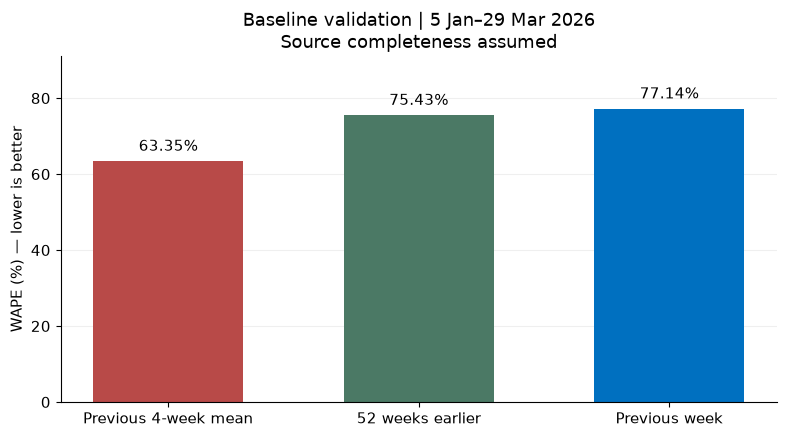

In [37]:
colors = {"baseline_last_week": "#0070C0", "baseline_mean_4": "#B84A48", "baseline_lag_52": "#4B7965"}
labels = {"baseline_last_week": "Previous week", "baseline_mean_4": "Previous 4-week mean", "baseline_lag_52": "52 weeks earlier"}
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar([labels[n] for n in overall_metrics["model_name"]], overall_metrics["WAPE_pct"],
              color=[colors[n] for n in overall_metrics["model_name"]], width=.6)
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in overall_metrics["WAPE_pct"]], padding=5)
ax.set_ylim(0, overall_metrics["WAPE_pct"].max() * 1.18)
ax.set_ylabel("WAPE (%) — lower is better")
ax.set_title("Baseline validation | 5 Jan–29 Mar 2026" +
             ("\nSource completeness assumed" if COVERAGE_MODE == "assumed_complete" else ""))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "baseline_validation.png", dpi=160)
plt.show()

### 12 导出和记录复现信息
本格会在`pal_steps_9_10_outputs`中保存周度面板、训练验证特征、特征名单、逐行baseline预测、指标和运行清单。不会输出测试期评价。

预先保存X列名能避免成员各自加列。后续模型阶段在每折训练数据内拟合编码和插补；不能把全部训练验证混在一起先fit预处理。

In [38]:
panel.to_csv(OUTPUT_DIR / "weekly_panel.csv", index=False)
train_valid.to_csv(OUTPUT_DIR / "features_train_validation.csv", index=False)
feature_dictionary.to_csv(OUTPUT_DIR / "feature_dictionary.csv", index=False)
predictions.to_csv(OUTPUT_DIR / "baseline_validation_predictions.csv", index=False)
fold_metrics.to_csv(OUTPUT_DIR / "baseline_validation_by_fold.csv", index=False)
overall_metrics.to_csv(OUTPUT_DIR / "baseline_validation_overall.csv", index=False)
manifest = {"source": source_description, "coverage_mode": COVERAGE_MODE,
    "cohort_rule": "first13weeks active>=8; top100stores then top5categories by positive volume; observed calibration pairs",
    "n_pairs": n_pairs, "panel_rows": len(panel), "validation_rows_per_baseline": len(validation),
    "validation_start": "2026-01-05", "validation_end": "2026-03-29",
    "selected_baseline": best_baseline, "target": "positive bottles per store-category-week",
    "forecast_protocol": "rolling one week ahead with observed prior actuals",
    "aggregate_scope": "fixed cohort only", "std_ddof": 0,
    "model_features": MODEL_FEATURES, "baseline_columns": BASELINES,
    "software": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__}}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "model_feature_names.json").write_text(json.dumps(MODEL_FEATURES, ensure_ascii=False, indent=2), encoding="utf-8")
print("文件已写入", OUTPUT_DIR)
print("训练验证特征行数", len(train_valid), "；核心X列数", len(MODEL_FEATURES))

文件已写入 C:\Users\sadie\Desktop\PAL\pal_steps_9_10_outputs
训练验证特征行数 25296 ；核心X列数 21
